*  DSC550-T302 Data Mining (2265-1)
*  Term Project: Term Project Milestone 1: Data Selection and EDA
*  David Jorgensen

# Term Project

## Project Description

Water scarcity is one of the defining resource challenges facing the American West. Utah, as an arid state that depends heavily on snowpack-fed rivers and reservoirs, is particularly vulnerable. At the same time, Utah has emerged as a rapidly growing technology and energy hub, attracting large-scale data centers drawn by land availability, tax incentives, and access to power. Nuclear energy is also being revisited as a low-carbon baseload option, with proposed sites in the region. Both data centers and nuclear power plants are significant industrial water consumers: nuclear plants use water for steam generation and cooling, while data centers rely on evaporative cooling systems that can consume millions of gallons per day at scale. As these facilities grow in number and capacity, their cumulative draw on Utah's already-stressed watersheds becomes a pressing concern for water managers, state regulators, and communities that depend on those same water sources.

This project addresses the following question: **to what extent does thermoelectric water consumption, from nuclear power plants and large industrial facilities such as data centers, reduce effective water availability in Utah watersheds, and can we predict the impact of future growth in that consumption?** Using watershed-level water availability and consumption data across Utah's 2,558 HUC12 watersheds from 2010 to 2019, alongside thermoelectric water withdrawal and consumption records for the same watersheds and time period, the goal is to quantify the relationship between industrial thermoelectric demand and watershed water availability.

The **target variable** for the predictive model is net water availability at the watershed level, defined as the difference between natural water availability (mm/month) and total water consumption (mm/month). This metric captures how much usable water remains in a watershed after human demand, including thermoelectric consumption, is accounted for. By building a regression model with thermoelectric consumption (in million gallons per day) as a key predictor, alongside year and watershed-level controls for natural variability, the model will estimate how each additional unit of thermoelectric demand reduces net availability. The resulting model can then be applied to project water stress scenarios as data center capacity and nuclear output expand in Utah over the coming decades.

The primary stakeholders for this analysis are Utah water resource managers, the Utah Division of Water Resources, environmental planning agencies, and technology companies conducting water impact assessments for proposed facilities. Accurate predictions of thermoelectric water stress will support sustainable siting decisions and long-term water allocation planning in a state where demand is rising and supply is increasingly uncertain.

**Data Sources**

- United States Geological Survey (USGS):
  - [Model: Thermoelectric Power Water-Use Model](https://water.usgs.gov/nwaa-data/data-catalog/sector/water-use/model/wu-thermoelectric/)
  - [Model: National Water Availability Assessment Outputs (CONUS 2025)](https://water.usgs.gov/nwaa-data/data-catalog/sector/integrated-water-availability/model/iwa-assessment-outputs-conus-2025/)
- Western Resource Advocates (WRA):
  - [Data Center Impacts in the West: Policy Solutions for Water and Energy Use](https://westernresourceadvocates.org/wp-content/uploads/2025/08/2025_DataCenter_FactSheet_UT.pdf)
- Salt Lake Tribune (SLT):
  - [Can Utah become a data center hub without draining its water supply?](https://www.sltrib.com/news/politics/2026/01/12/does-utah-have-enough-water-be/)
- Stanford University:
  - [Nuclear Reactor Water Usage and the Implications of Limited Water Availability](http://large.stanford.edu/courses/2013/ph241/abdul-khabir2/)

## Milestone 1: Data Selection and EDA

In [44]:
# Libraries
import pandas as pd
import matplotlib.pyplot as plt
import os

In [45]:
# Data Prep

current_directory = os.getcwd()
print(current_directory)

# Load utah-water datasets
utah_water_1 = pd.read_csv('data/utah-water/nwaa_data_1_of_5.csv')
utah_water_2 = pd.read_csv('data/utah-water/nwaa_data_2_of_5.csv')
utah_water_3 = pd.read_csv('data/utah-water/nwaa_data_3_of_5.csv')
utah_water_4 = pd.read_csv('data/utah-water/nwaa_data_4_of_5.csv')
utah_water_5 = pd.read_csv('data/utah-water/nwaa_data_5_of_5.csv')
utah_water = pd.concat([utah_water_1, utah_water_2, utah_water_3, utah_water_4, utah_water_5], ignore_index=True)

# Load thermoelectric water usage datasets (power plants including nuclear)
# tewdftot_mgd = total withdrawal (MGD), tecuftot_mgd = total consumption (MGD)
thermo_1 = pd.read_csv('data/thermoelectric-water/nwaa_data_1_of_5(1).csv')
thermo_2 = pd.read_csv('data/thermoelectric-water/nwaa_data_2_of_5(1).csv')
thermo_3 = pd.read_csv('data/thermoelectric-water/nwaa_data_3_of_5(1).csv')
thermo_4 = pd.read_csv('data/thermoelectric-water/nwaa_data_4_of_5(1).csv')
thermo_5 = pd.read_csv('data/thermoelectric-water/nwaa_data_5_of_5(1).csv')
thermo_water = pd.concat([thermo_1, thermo_2, thermo_3, thermo_4, thermo_5], ignore_index=True)

print('Utah water shape:', utah_water.shape)
print('Thermoelectric water shape:', thermo_water.shape)
utah_water.head()

/home/djorgs/Documents/school/datasci-school/550/term-project
Utah water shape: (25580, 4)
Thermoelectric water shape: (28138, 4)


,huc12_id,year,availab_mm/mo,consum_mm/mo
0,140100051703,2010,0.478186,0.0
1,140100051703,2011,1.742365,0.0
2,140100051703,2012,0.385197,0.0
3,140100051703,2013,0.203595,0.0
4,140100051703,2014,0.644711,0.0


In [46]:
# Merge utah water and thermoelectric data on watershed and year
# Both datasets share the same 2558 Utah watersheds covering 2010-2019
water = pd.merge(utah_water, thermo_water, on=['huc12_id', 'year'], how='left')
water[['tewdftot_mgd', 'tecuftot_mgd']] = water[['tewdftot_mgd', 'tecuftot_mgd']].fillna(0)

print('Merged shape:', water.shape)
print('Watershed-years with thermoelectric activity:', (water['tecuftot_mgd'] > 0).sum())
water.head()

Merged shape: (25580, 6)
Watershed-years with thermoelectric activity: 76


,huc12_id,year,availab_mm/mo,consum_mm/mo,tewdftot_mgd,tecuftot_mgd
0,140100051703,2010,0.478186,0.0,0.0,0.0
1,140100051703,2011,1.742365,0.0,0.0,0.0
2,140100051703,2012,0.385197,0.0,0.0,0.0
3,140100051703,2013,0.203595,0.0,0.0,0.0
4,140100051703,2014,0.644711,0.0,0.0,0.0


In [47]:
# Aggregate by year for statewide trend analysis
# availab_mm/mo and consum_mm/mo are depth rates, average across watersheds
# tewdftot_mgd and tecuftot_mgd are volumetric, sum for statewide total
yearly = water.groupby('year').agg(
    avg_availability=('availab_mm/mo', 'mean'),
    avg_consumption=('consum_mm/mo', 'mean'),
    total_thermo_withdrawal_mgd=('tewdftot_mgd', 'sum'),
    total_thermo_consumption_mgd=('tecuftot_mgd', 'sum')
).reset_index()

yearly['water_usage_pct'] = (yearly['avg_consumption'] / yearly['avg_availability']) * 100
yearly

,year,avg_availability,avg_consumption,total_thermo_withdrawal_mgd,total_thermo_consumption_mgd,water_usage_pct
0,2010,3.807921,0.566424,59.924308,42.803077,14.874885
1,2011,8.523798,0.485237,57.124303,40.803074,5.692735
2,2012,2.675353,0.476012,58.349173,41.677980,17.792486
3,2013,2.711678,0.473493,61.503724,43.931231,17.461267
4,2014,3.386075,0.522941,60.353813,43.109867,15.443879
5,2015,3.500538,0.543855,59.473624,42.481160,15.536330
6,2016,3.916924,0.603081,50.603460,36.145329,15.396807
7,2017,6.607869,0.543559,50.297161,35.926544,8.225930
8,2018,1.703286,0.604023,52.907672,37.791195,35.462210
9,2019,6.914018,0.542720,50.180954,35.843539,7.849568


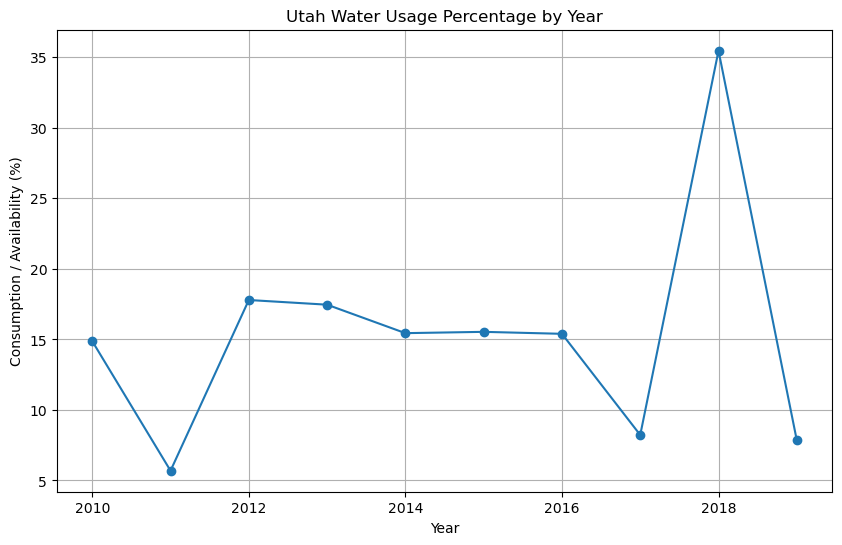

In [48]:
plt.figure(figsize=(10, 6))
plt.plot(yearly['year'], yearly['water_usage_pct'], marker='o')
plt.title('Utah Water Usage Percentage by Year')
plt.xlabel('Year')
plt.ylabel('Consumption / Availability (%)')
plt.grid(True)
plt.show()

### Chart 1: Utah Water Usage Percentage by Year

This chart shows total water consumption as a percentage of total water availability averaged across all Utah watersheds each year. The ratio swings dramatically, from under 6% in the wet year of 2011 to over 35% in the dry year of 2018, despite relatively stable year-to-year consumption (see aggregation table above). This tells us that **natural precipitation variability, not consumption, dominates this ratio**.

**Research implication:** To isolate the contribution of data centers and nuclear power plants, we cannot rely on statewide availability ratios alone. We need to control for natural variability (e.g., precipitation or snowpack as co-variates) or focus analysis at the individual watershed level where thermoelectric use occurs.

In [49]:
yearly['flow_rate'] = yearly['avg_availability'].pct_change() * 100
yearly[['year', 'avg_availability', 'flow_rate']]

,year,avg_availability,flow_rate
0,2010,3.807921,NaN
1,2011,8.523798,123.843843
2,2012,2.675353,-68.613136
3,2013,2.711678,1.357789
4,2014,3.386075,24.870065
5,2015,3.500538,3.380417
6,2016,3.916924,11.894900
7,2017,6.607869,68.700471
8,2018,1.703286,-74.223371
9,2019,6.914018,305.922351


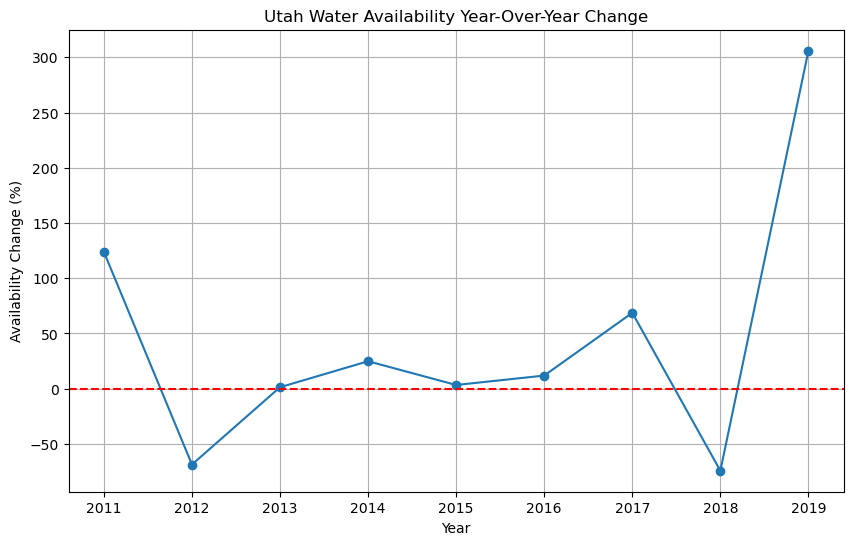

In [50]:
plt.figure(figsize=(10, 6))
plt.plot(yearly['year'], yearly['flow_rate'], marker='o')
plt.title('Utah Water Availability Year-Over-Year Change')
plt.xlabel('Year')
plt.ylabel('Availability Change (%)')
plt.axhline(y=0, color='r', linestyle='--')
plt.grid(True)
plt.show()

### Chart 2: Utah Water Availability Year-Over-Year Change

This chart shows the year-over-year percent change in average watershed water availability. Swings are extreme: +124% from 2010 to 2011, −69% from 2011 to 2012, and +306% from 2018 to 2019. These are precipitation and snowmelt signals, not consumption signals.

**Research implication:** Because natural availability is so volatile, any predictive model attributing consumption effects to data centers or nuclear plants will need strong climate controls (e.g., precipitation, SWE) to avoid confounding. This also motivates looking at *net* availability (`availab_mm/mo − consum_mm/mo`) at the watershed level rather than statewide averages.

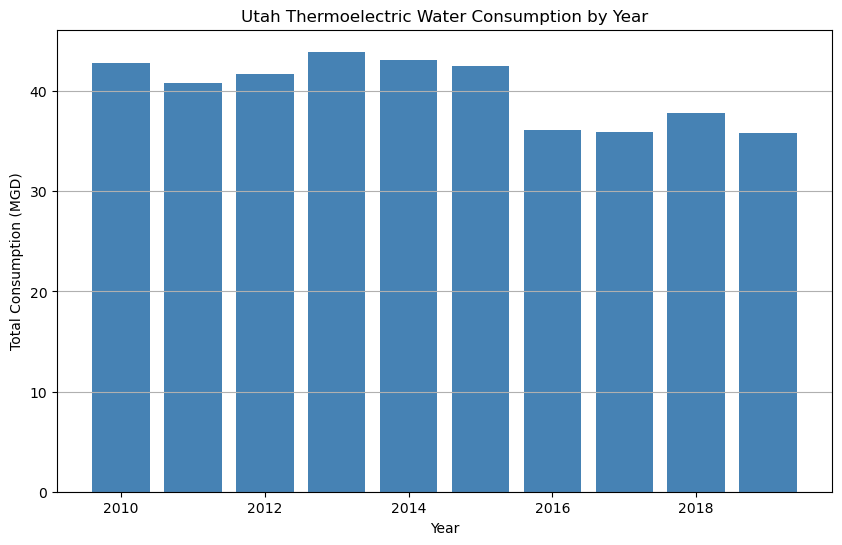

In [51]:
plt.figure(figsize=(10, 6))
plt.bar(yearly['year'], yearly['total_thermo_consumption_mgd'], color='steelblue')
plt.title('Utah Thermoelectric Water Consumption by Year')
plt.xlabel('Year')
plt.ylabel('Total Consumption (MGD)')
plt.grid(True, axis='y')
plt.show()

### Chart 3: Utah Thermoelectric Water Consumption by Year

This chart shows the total statewide thermoelectric water consumption in million gallons per day (MGD), representing water consumed by large thermal power plants (including nuclear). Consumption is relatively stable at 36–44 MGD with a slight declining trend since 2013, likely reflecting efficiency improvements or reduced output at existing facilities.

**Research implication:** This downward trend in thermoelectric use contrasts with the expected *growth* in data center water demand, which is not yet captured here. Data centers cool servers using evaporative cooling systems and can consume significant water at scale. Obtaining facility-level data center water use records (e.g., from utility filings or corporate sustainability reports) is the key next data collection step to separate nuclear plant effects from data center effects.

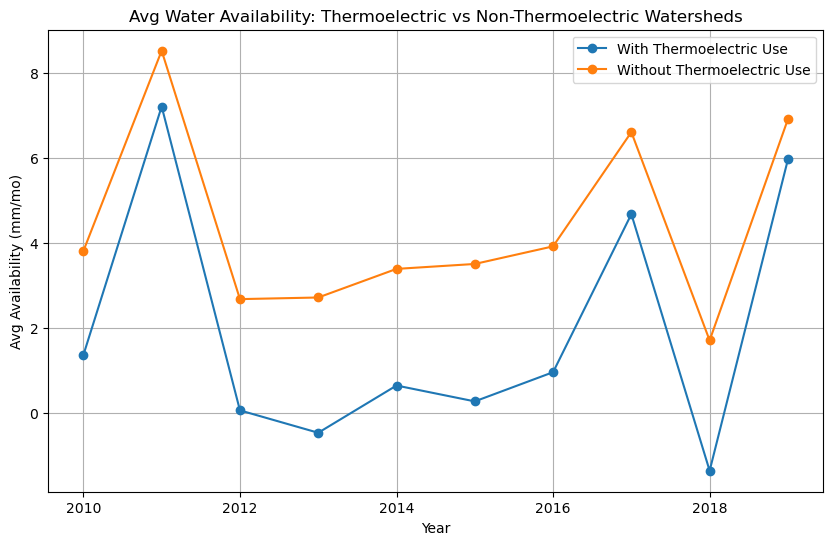

In [52]:
water['has_thermo'] = water['tecuftot_mgd'] > 0
thermo_compare = water.groupby(['year', 'has_thermo'])['availab_mm/mo'].mean().reset_index()

fig, ax = plt.subplots(figsize=(10, 6))
for has, label in [(True, 'With Thermoelectric Use'), (False, 'Without Thermoelectric Use')]:
    subset = thermo_compare[thermo_compare['has_thermo'] == has]
    ax.plot(subset['year'], subset['availab_mm/mo'], marker='o', label=label)
ax.set_title('Avg Water Availability: Thermoelectric vs Non-Thermoelectric Watersheds')
ax.set_xlabel('Year')
ax.set_ylabel('Avg Availability (mm/mo)')
ax.legend()
ax.grid(True)
plt.show()

### Chart 4: Water Availability — Thermoelectric vs. Non-Thermoelectric Watersheds

This chart compares average water availability in the 8 watersheds that contain thermoelectric facilities against the remaining 2,550 watersheds. Both groups track closely in most years, following the same precipitation-driven patterns. However, if thermoelectric consumption were meaningfully stressing a watershed, we would expect the thermoelectric group to show a systematically lower or more rapidly declining availability over time.

**Research implication:** This is the most direct precursor to our predictive model. The next step is to build a regression at the watershed-year level using `tecuftot_mgd` (and eventually data center water use) as a predictor of `availab_mm/mo` or net availability, controlling for year effects. Watersheds with the highest thermoelectric consumption, particularly those containing nuclear plants or large data center cooling systems, should be the primary focus for model training and interpretation.